In [48]:
import matplotlib.pyplot as plt
import pandas as pd

In [49]:
data = pd.read_csv(
    "../data/raw/regularite-mensuelle-tgv-aqst.csv", sep=";", decimal=","
)
data.head(5)

,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,...,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.24780854,...,110,6.511117534,44,8,36.13445378,31.09243697,10.92436975,15.96638655,5.042016807,0.840336134
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.479968701,...,32,5.363539095,9,4,20.0,35.0,16.66666667,16.66666667,8.333333333,3.333333333
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.23968254,...,11,2.938053097,6,1,22.22222222,27.77777778,16.66666667,16.66666667,5.555555556,11.11111111
3,2018-01,National,PARIS MONTPARNASSE,NANTES,124,508,3,NaN,71,7.235211268,...,39,5.292211221,18,8,33.33333333,22.22222222,16.66666667,20.37037037,5.555555556,1.851851852
4,2018-01,National,POITIERS,PARIS MONTPARNASSE,94,472,4,NaN,224,6.784672619,...,42,4.882371795,10,0,15.78947368,45.61403509,19.29824561,15.78947368,1.754385965,1.754385965


In [50]:
data.dtypes

Date                                                                                               str
Service                                                                                            str
Gare de départ                                                                                     str
Gare d'arrivée                                                                                     str
Durée moyenne du trajet                                                                          int64
Nombre de circulations prévues                                                                   int64
Nombre de trains annulés                                                                         int64
Commentaire annulations                                                                        float64
Nombre de trains en retard au départ                                                             int64
Retard moyen des trains en retard au départ                              

In [51]:
data["Service"].value_counts()

Service
National         11339
International     1568
Name: count, dtype: int64

**Quelles gares de départ concentrent le plus de trains "responsables" de retards par rapport aux gares qui subissent des correspondances en cascade ?**

## Etude de la question

1. Reformulation : Quelles gares de départ concentrent le plus de trains causant les retards, par rapport aux gares dont le retard est subit des train provenant des gares en amont dans le trajet.
2. Définition opérationnelle : 
   * Train responsables de retards : Trains causant des retards, dont le retard n'est pas hérité d'une autre liaison. colonnes concernés : **Pour une liaison A vers B le Nombre de trains en retard à l'arrivée x prct retard pour cause gestion infrastructure,  matériel roulant, et gestion trafic donne le nombre de train responsables de retard émis par A pour cette liaison (Implique donc de faire ensuite un groupby surA)**.
  
   * Gare qui subit des correspondances en cascade : Gare dans le trajet des trains, dont le retard à l'arrivée est hérité de la gare en amont. colonnes concernés : **Pour une liaison A vers B, Nmbre de train en retard à l'arrivée x prct reatard pour cause prise en compte voyageurs (affluence, gestions psh, correspondance}, et gestion en gare et réuttilisation de matériel donne le nombre de train en retard Subit Par A pour cette liaison  (Implique donc de faire ensuite un groupby surA)**
  
   * "Concentrer" : Volume de train strict, pas le taux, car la question porte littérallement sur le volume.
3.  Périmètre : Service : National car on doit se centrer essentiellement sur les gares francais. période : toute la période disponible. Puis une analyse par année et ensuite par mois pour voir si globalement, le pattern se repète ou s'il y'a des différences. En plus une anlyse couvrant toute la période disponible sans 2020. 
   
4.  **Hypothèses** : 
   * Les pourcentage par causes donnés sont calculé à partir du nombre de retard à l'arrivée
   * les retards pour cause externes comptes pour une troisième catégorie de retard. Il y'a donc 3 catégorie de retard, les retard subis, les retard responsables, et les retards pour causes externes ne pouvant pas etre tranchée comme héritée ou non. 

5. **Limite** : L'effet de la taille des gare n'est pas pris en compte, on se concentre strictement sur le volume des trains. pour une prise en compte de la taille des gares il faudrait voir avec la question sur le score de fiabilité. 

6. **Critères de réponses** : Un classement sur le nombre de retard Hérité, et un autre sur le nombre de retard non Hérité (les 15 premiers gares de chaque classements). Globalement, puis en excluant l'année 2020, puis par année, et enfin éventuellement par mois. Un croisement entre les deux listes, et une troisième liste sur la part de chaque catégorie de retard pour chaque gares. 

7. **Livrables** : Les tableaux et le diagramme en barre des différentes listes + Messages de synthèse

## Prétraitement des données 

In [52]:
print(data.shape)
print("=========================")
print(data.dtypes)

(12907, 26)
Date                                                                                               str
Service                                                                                            str
Gare de départ                                                                                     str
Gare d'arrivée                                                                                     str
Durée moyenne du trajet                                                                          int64
Nombre de circulations prévues                                                                   int64
Nombre de trains annulés                                                                         int64
Commentaire annulations                                                                        float64
Nombre de trains en retard au départ                                                             int64
Retard moyen des trains en retard au départ                  

In [53]:
data.head(5)

,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,...,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.24780854,...,110,6.511117534,44,8,36.13445378,31.09243697,10.92436975,15.96638655,5.042016807,0.840336134
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.479968701,...,32,5.363539095,9,4,20.0,35.0,16.66666667,16.66666667,8.333333333,3.333333333
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.23968254,...,11,2.938053097,6,1,22.22222222,27.77777778,16.66666667,16.66666667,5.555555556,11.11111111
3,2018-01,National,PARIS MONTPARNASSE,NANTES,124,508,3,NaN,71,7.235211268,...,39,5.292211221,18,8,33.33333333,22.22222222,16.66666667,20.37037037,5.555555556,1.851851852
4,2018-01,National,POITIERS,PARIS MONTPARNASSE,94,472,4,NaN,224,6.784672619,...,42,4.882371795,10,0,15.78947368,45.61403509,19.29824561,15.78947368,1.754385965,1.754385965


In [ ]:
COLONNES = {
    "Date": "date",
    "Service": "service",
    "Gare de départ": "gare_depart",
    "Gare d'arrivée": "gare_arrivee",
    "Durée moyenne du trajet": "duree_trajet",
    "Nombre de circulations prévues": "circ_prevues",
    "Nombre de trains annulés": "annules",
    "Nombre de trains en retard au départ": "ret_dep",
    "Nombre de trains en retard à l'arrivée": "ret_arr",
    "Retard moyen des trains en retard à l'arrivée": "ret_moy_arr",
    "Prct retard pour causes externes": "pct_externes",
    "Prct retard pour cause infrastructure": "pct_infra",
    "Prct retard pour cause gestion trafic": "pct_trafic",
    "Prct retard pour cause matériel roulant": "pct_materiel",
    (
        "Prct retard pour cause gestion en gare et "
        "réutilisation de matériel"
    ): "pct_gare_reutil",
    (
        "Prct retard pour cause prise en compte voyageurs "
        "(affluence, gestions PSH, correspondances)"
    ): "pct_voyageurs",
}

PCT_COLS = [c for c in COLONNES.values() if c.startswith("pct_")]
COLONNES_NUMERIQUES = [
    "duree_trajet",
    "circ_prevues",
    "annules",
    "ret_dep",
    "ret_arr",
    "ret_moy_arr",
] + PCT_COLS

CAUSES_NON_HERITEES = ["pct_infra", "pct_trafic", "pct_materiel"]
CAUSES_HERITEES = ["pct_gare_reutil", "pct_voyageurs"]
CAUSES_EXTERNES = ["pct_externes"]

PCT_COLS = [c for c in COLONNES.values() if c.startswith("pct_")]
COLONNES_NUMERIQUES = [
    "duree_trajet",
    "circ_prevues",
    "annules",
    "ret_dep",
    "ret_arr",
    "ret_moy_arr",
] + PCT_COLS

CAUSES_NON_HERITEES = ["pct_infra", "pct_trafic", "pct_materiel"]
CAUSES_HERITEES = ["pct_gare_reutil", "pct_voyageurs"]
CAUSES_EXTERNES = ["pct_externes"]

In [73]:
table = data.rename(columns=COLONNES)
table["date"] = pd.to_datetime(table["date"], format="%Y-%m")

table["annee"] = table["date"].dt.year
table = table[table["service"] == "National"].copy()

table[PCT_COLS] = table[PCT_COLS].apply(pd.to_numeric, errors="coerce")

table["retard_heritee"] = table["ret_arr"] * (table[CAUSES_HERITEES].sum(axis=1) / 100)
table["retard_non_heritee"] = table["ret_arr"] * (
    table[CAUSES_NON_HERITEES].sum(axis=1) / 100
)
table["retard_externe"] = table["ret_arr"] * (table[CAUSES_EXTERNES].sum(axis=1) / 100)

table_globale = (
    table[
        [
            "date",
            "gare_depart",
            "retard_heritee",
            "retard_non_heritee",
            "retard_externe",
        ]
    ]
    .groupby(["gare_depart"])
    .agg(
        {"retard_heritee": "sum", "retard_non_heritee": "sum", "retard_externe": "sum"}
    )
    .reset_index()
)
table_globale["taux_heritee"] = table_globale["retard_heritee"] / (
    table_globale["retard_heritee"]
    + table_globale["retard_non_heritee"]
    + table_globale["retard_externe"]
)
table_globale["taux_non_heritee"] = table_globale["retard_non_heritee"] / (
    table_globale["retard_heritee"]
    + table_globale["retard_non_heritee"]
    + table_globale["retard_externe"]
)


table_annee = (
    table[
        [
            "annee",
            "gare_depart",
            "retard_heritee",
            "retard_non_heritee",
            "retard_externe",
        ]
    ]
    .groupby(["annee", "gare_depart"])
    .agg(
        {"retard_heritee": "sum", "retard_non_heritee": "sum", "retard_externe": "sum"}
    )
    .reset_index()
)

table_mois = (
    table[
        [
            "date",
            "gare_depart",
            "retard_heritee",
            "retard_non_heritee",
            "retard_externe",
        ]
    ]
    .groupby(["date", "gare_depart"])
    .agg(
        {"retard_heritee": "sum", "retard_non_heritee": "sum", "retard_externe": "sum"}
    )
    .reset_index()
)

In [56]:
table_annee.head(5)

,annee,gare_depart,retard_heritee,retard_non_heritee,retard_externe
0,2018,AIX EN PROVENCE TGV,44.837561,350.851141,157.311297
1,2018,ANGERS SAINT LAUD,68.412077,611.018063,258.569860
2,2018,ANGOULEME,64.858621,405.188813,129.952566
3,2018,ANNECY,27.953250,327.814841,189.231909
4,2018,ARRAS,72.425902,748.497586,144.076512


In [57]:
table_globale.head(5)

,gare_depart,retard_heritee,retard_non_heritee,retard_externe,taux_heritee
0,AIX EN PROVENCE TGV,987.630695,2826.606417,1316.762888,0.192483
1,ANGERS SAINT LAUD,1121.336126,4308.587831,2003.076043,0.150859
2,ANGOULEME,891.813945,2751.124849,1027.061206,0.190967
3,ANNECY,178.502630,1847.198090,811.299280,0.062920
4,ARRAS,1284.220740,6562.071587,1287.707674,0.140598


In [58]:
print(table[PCT_COLS].isna().sum().sum())

0


In [59]:
table["ecart_categories"] = table["ret_arr"] - table[
    ["retard_heritee", "retard_non_heritee", "retard_externe"]
].sum(axis=1)

In [60]:
print(table[["date", "gare_depart"]][table["ecart_categories"].abs() > 0.5])

            date           gare_depart
536   2018-05-01      BELLEGARDE (AIN)
2649  2019-09-01      BORDEAUX ST JEAN
3466  2020-04-01            PARIS LYON
3510  2020-04-01             PARIS EST
3735  2020-06-01                ANNECY
3759  2020-06-01             DUNKERQUE
3761  2020-06-01             TOURCOING
12405 2026-05-01      BORDEAUX ST JEAN
12430 2026-06-01        LYON PART DIEU
12480 2026-06-01  MARSEILLE ST CHARLES
12487 2026-06-01    PARIS MONTPARNASSE
12512 2026-06-01    PARIS MONTPARNASSE
12514 2026-06-01    PARIS MONTPARNASSE
12672 2026-08-01                 LILLE
12692 2026-08-01  MARSEILLE ST CHARLES
12758 2026-08-01    PARIS MONTPARNASSE
12807 2026-09-01             TOURCOING
12814 2026-09-01                 LILLE
12886 2026-09-01    VALENCE ALIXAN TGV


In [61]:
table.groupby("annee")["date"].nunique()

annee
2018    12
2019    12
2020    12
2021    12
2022    12
2023    12
2024    12
2025    12
2026     9
Name: date, dtype: int64

In [62]:
table_globale["gare_depart"].unique()

<ArrowStringArray>
[           'AIX EN PROVENCE TGV',              'ANGERS SAINT LAUD',
                      'ANGOULEME',                         'ANNECY',
                          'ARRAS',                    'AVIGNON TGV',
                      'BARCELONA',               'BELLEGARDE (AIN)',
     'BESANCON FRANCHE COMTE TGV',               'BORDEAUX ST JEAN',
                          'BREST',      'CHAMBERY CHALLES LES EAUX',
                    'DIJON VILLE',                          'DOUAI',
                      'DUNKERQUE',                       'GRENOBLE',
              'LA ROCHELLE VILLE',                          'LAVAL',
 'LE CREUSOT MONTCEAU MONTCHANIN',                        'LE MANS',
                          'LILLE',                 'LYON PART DIEU',
                    'MACON LOCHE',                'MARNE LA VALLEE',
           'MARSEILLE ST CHARLES',                           'METZ',
                    'MONTPELLIER',                 'MULHOUSE VILLE',
               

In [63]:
table_annee[["gare_depart", "annee"]].nunique()

gare_depart    52
annee           9
dtype: int64

## Ananlyse des données

### Avec l'annee 2020

#### Comparaison globale

In [70]:
COULEURS = {
    "non_heritee": "#2a6f97",
    "heritee": "#d9822b",
    "taux_heritee": "#8c564b",
    "taux_non_heritee": "#1f77b4",
}

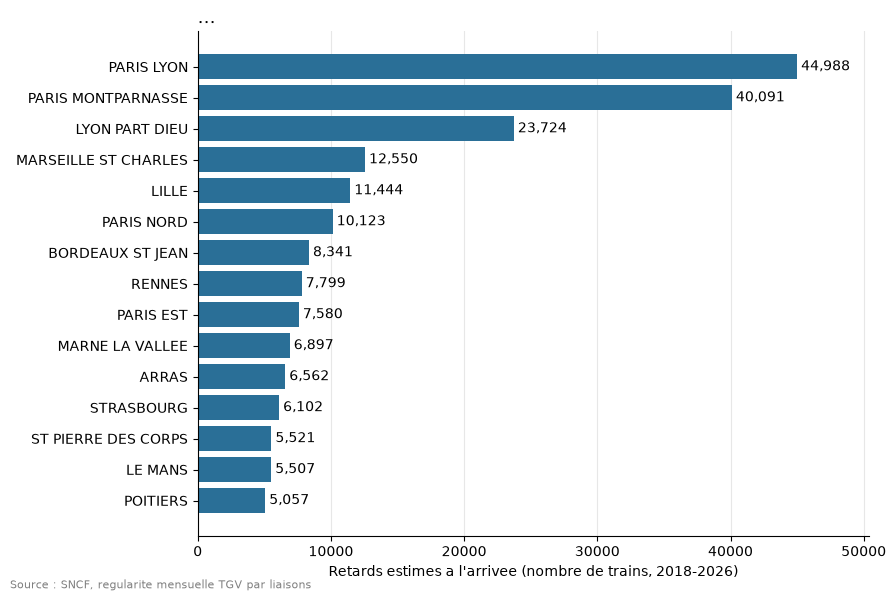

In [71]:
top = (
    table_globale.nlargest(15, "retard_non_heritee")
    .set_index("gare_depart")["retard_non_heritee"]
    .sort_values()
)

fig, ax = plt.subplots(figsize=(9, 6))
barres = ax.barh(top.index, top.values, color=COULEURS["non_heritee"])
ax.bar_label(barres, fmt="{:,.0f}", padding=3)

ax.set_title("...", loc="left", fontsize=13)
ax.set_xlabel("Retards estimes a l'arrivee (nombre de trains, 2018-2026)")
ax.set_xlim(0, top.max() * 1.12)
ax.spines[["top", "right"]].set_visible(False)
ax.xaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
fig.text(
    0.01,
    0.01,
    "Source : SNCF, regularite mensuelle TGV par liaisons",
    fontsize=8,
    color="gray",
)

fig.tight_layout()
plt.show()

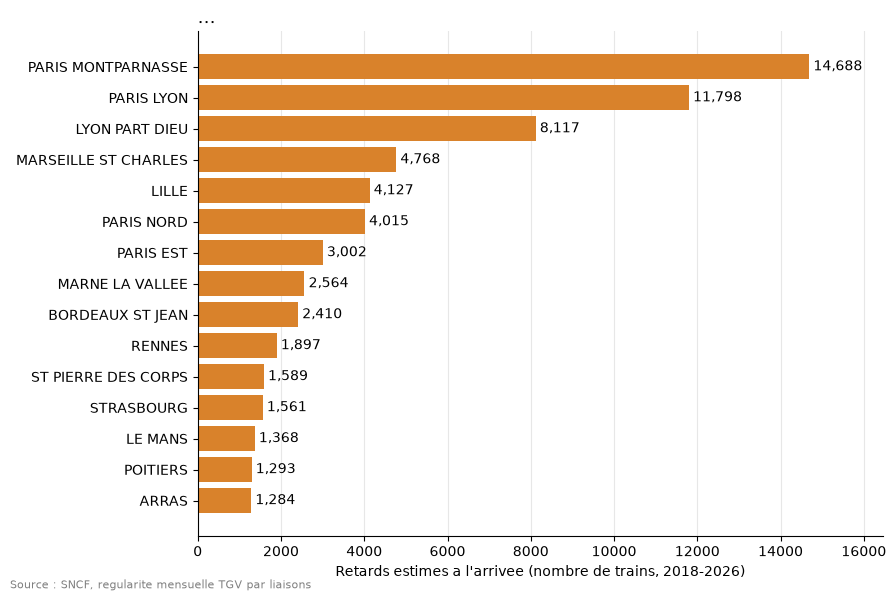

In [65]:
top = (
    table_globale.nlargest(15, "retard_heritee")
    .set_index("gare_depart")["retard_heritee"]
    .sort_values()
)

fig, ax = plt.subplots(figsize=(9, 6))
barres = ax.barh(top.index, top.values, color=COULEURS["heritee"])
ax.bar_label(barres, fmt="{:,.0f}", padding=3)

ax.set_title("...", loc="left", fontsize=13)
ax.set_xlabel("Retards estimes a l'arrivee (nombre de trains, 2018-2026)")
ax.set_xlim(0, top.max() * 1.12)
ax.spines[["top", "right"]].set_visible(False)
ax.xaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
fig.text(
    0.01,
    0.01,
    "Source : SNCF, regularite mensuelle TGV par liaisons",
    fontsize=8,
    color="gray",
)

fig.tight_layout()
plt.show()

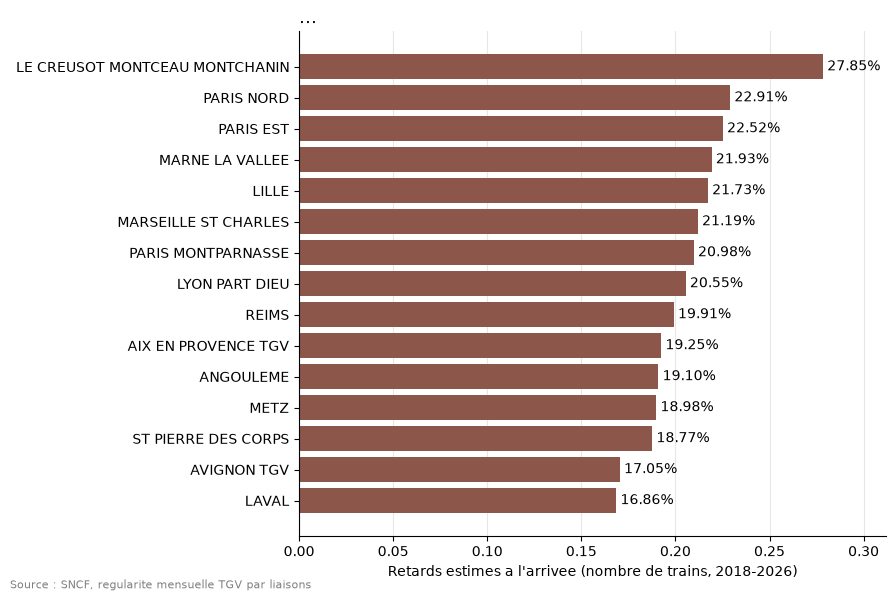

In [68]:
top = (
    table_globale.nlargest(15, "taux_heritee")
    .set_index("gare_depart")["taux_heritee"]
    .sort_values()
)

fig, ax = plt.subplots(figsize=(9, 6))
barres = ax.barh(top.index, top.values, color=COULEURS["taux_heritee"])
ax.bar_label(barres, fmt="{:.2%}", padding=3)

ax.set_title("...", loc="left", fontsize=13)
ax.set_xlabel("Retards estimes a l'arrivee (nombre de trains, 2018-2026)")
ax.set_xlim(0, top.max() * 1.12)
ax.spines[["top", "right"]].set_visible(False)
ax.xaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
fig.text(
    0.01,
    0.01,
    "Source : SNCF, regularite mensuelle TGV par liaisons",
    fontsize=8,
    color="gray",
)

fig.tight_layout()
plt.show()

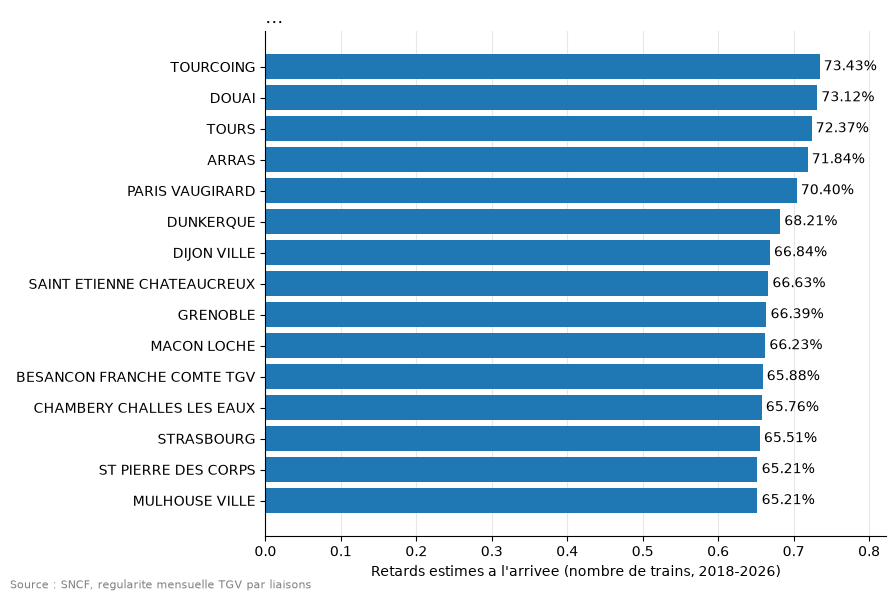

In [74]:
top = (
    table_globale.nlargest(15, "taux_non_heritee")
    .set_index("gare_depart")["taux_non_heritee"]
    .sort_values()
)

fig, ax = plt.subplots(figsize=(9, 6))
barres = ax.barh(top.index, top.values, color=COULEURS["taux_non_heritee"])
ax.bar_label(barres, fmt="{:.2%}", padding=3)

ax.set_title("...", loc="left", fontsize=13)
ax.set_xlabel("Retards estimes a l'arrivee (nombre de trains, 2018-2026)")
ax.set_xlim(0, top.max() * 1.12)
ax.spines[["top", "right"]].set_visible(False)
ax.xaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
fig.text(
    0.01,
    0.01,
    "Source : SNCF, regularite mensuelle TGV par liaisons",
    fontsize=8,
    color="gray",
)

fig.tight_layout()
plt.show()